# The code generates genome map with highlighted genes. 

- It is handy for structural biology of phages, like in https://www.biorxiv.org/content/10.64898/2026.04.10.717836v1.full 
- The code requires [DnaFeaturesViewer](https://github.com/Edinburgh-Genome-Foundry/DnaFeaturesViewer) package
- Input format: .gbk
- Output format: .svg file that can be adjusted in vector graphic editors, like Inkscape
- The example input file can be accessed via the corresponding article: [Smith DL, Rooks DJ, Fogg PC, Darby AC, Thomson NR, McCarthy AJ, Allison HE. Comparative genomics of Shiga toxin encoding bacteriophages. BMC Genomics. 2012 Jul 16;13:311. doi: 10.1186/1471-2164-13-311. PMID: 22799768; PMCID: PMC3430580.](https://pmc.ncbi.nlm.nih.gov/articles/PMC3430580) 

In [58]:
from dna_features_viewer import BiopythonTranslator
import pandas as pd

In [62]:
filename = "Genome_phi24B.gbk" # path to input GenBank file
seq_start = 20000
seq_end = 45000

# Dataframe with gene names and colors for plotting
gene_df = pd.DataFrame([
    ["APL45_gp57", "gp57", "#55ff00"],
    ["APL45_gp61", "gp61", "#0055ff"],
    ["APL45_gp62", "gp62", "#ff3C15"],
    ["APL45_gp64", "gp64", "#55ffff"],
    ["APL45_gp67", "gp67", "#fe218b"],
    ["APL45_gp69", "gp69", "#f6D32D"],
    ["APL45_gp72", "gp72", "#ff55ff"],
    ["APL45_gp84", "gp84", "#ffCf7D"],
], columns=["gene_tag", "gene_name", "color"])


In [60]:
# Querying BiopythonTranslator to filter and color desired genes based on gene_df

translator = BiopythonTranslator(
    features_filters=[lambda feature: (feature.type == "gene" and feature.qualifiers["locus_tag"][0] in gene_df.gene_tag.values)],
    features_properties=lambda feature: {"color": gene_df.loc[gene_df.gene_tag == feature.qualifiers["locus_tag"][0], "color"].values[0],
                                         "label": gene_df.loc[gene_df.gene_tag == feature.qualifiers["locus_tag"][0], "gene_name"].values[0]}
)

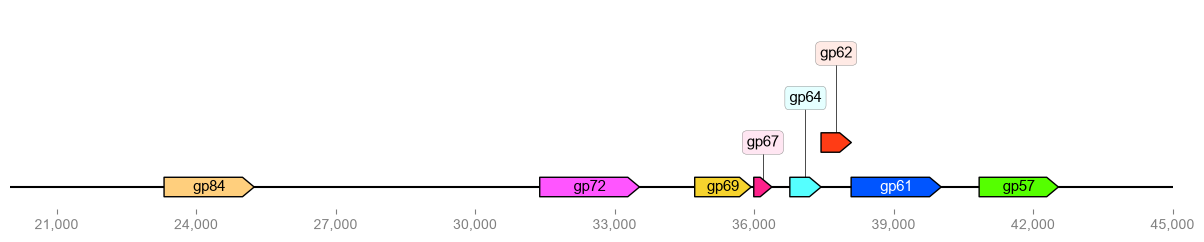

In [ ]:
# Plotting custom genes and saving the figure

graphic_record = translator.translate_record(filename).crop((seq_start, seq_end))

ax, _ = graphic_record.plot(figure_width=15, strand_in_label_threshold=0)
ax.figure.savefig("drawn_genome.svg")